# Chapter 4 — Training Models

这一章的问题是：**模型到底怎样从数据中学到参数？**

主线可以压缩成：

$$
\text{定义模型}
\longrightarrow
\text{定义损失函数}
\longrightarrow
\text{最小化损失}
\longrightarrow
\text{得到参数}
$$

本 notebook 用小型、可复现的实验连接数学与 scikit-learn 实现，覆盖线性回归、直接解、三种梯度下降、多项式回归、学习曲线、正则化、提前停止、Logistic Regression 与 Softmax Regression。

## 0. Setup

所有回归数据都在本地生成；分类使用 scikit-learn 内置的 Iris 数据，因此运行整本 notebook 不需要联网。

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.linear_model import (
    ElasticNet,
    Lasso,
    LinearRegression,
    LogisticRegression,
    Ridge,
    SGDRegressor,
)
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Linear Regression

线性回归假设预测是特征的加权和：

$$
\hat y = \theta_0 + \theta_1x_1 + \cdots + \theta_nx_n
= \boldsymbol{\theta}^{\mathsf T}\mathbf{x}
$$

训练时通常最小化均方误差：

$$
\operatorname{MSE}(\boldsymbol{\theta})
= \frac{1}{m}\sum_{i=1}^{m}
\left(\boldsymbol{\theta}^{\mathsf T}\mathbf{x}^{(i)}-y^{(i)}\right)^2
$$

下面生成接近 $y=4+3x$ 的带噪声数据。模型看不到真实参数，只能从样本中估计它们。

Estimated intercept: 3.949
Estimated slope:     3.038


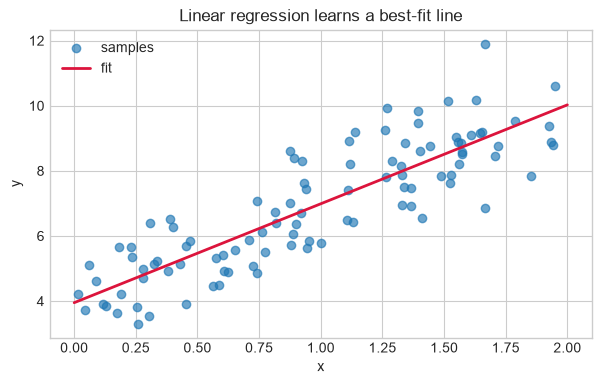

In [2]:
X = 2 * rng.random((100, 1))
y = 4 + 3 * X[:, 0] + rng.normal(0, 1, 100)

linear_model = LinearRegression()
linear_model.fit(X, y)

print(f"Estimated intercept: {linear_model.intercept_:.3f}")
print(f"Estimated slope:     {linear_model.coef_[0]:.3f}")

X_line = np.array([[0.0], [2.0]])
plt.figure(figsize=(7, 4))
plt.scatter(X, y, alpha=0.65, label="samples")
plt.plot(X_line, linear_model.predict(X_line), color="crimson", linewidth=2, label="fit")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear regression learns a best-fit line")
plt.legend()
plt.show()

## 2. Normal Equation and Pseudoinverse

给设计矩阵补上一列 1 以容纳截距，最小二乘的正规方程是：

$$
\hat{\boldsymbol{\theta}}
= (\mathbf X^{\mathsf T}\mathbf X)^{-1}\mathbf X^{\mathsf T}\mathbf y
$$

但 $\mathbf X^{\mathsf T}\mathbf X$ 可能不可逆或数值不稳定。实际更稳健的形式是 Moore–Penrose pseudoinverse：

$$
\hat{\boldsymbol{\theta}} = \mathbf X^+\mathbf y
$$

`np.linalg.pinv()` 基于 SVD；`LinearRegression` 也使用稳定的最小二乘求解，而不是显式计算矩阵逆。

In [3]:
X_b = np.c_[np.ones((len(X), 1)), X]
theta_normal = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
theta_pinv = np.linalg.pinv(X_b) @ y

parameter_comparison = pd.DataFrame(
    {
        "method": ["Normal equation", "Pseudoinverse", "LinearRegression"],
        "intercept": [theta_normal[0], theta_pinv[0], linear_model.intercept_],
        "slope": [theta_normal[1], theta_pinv[1], linear_model.coef_[0]],
    }
)
parameter_comparison.style.format({"intercept": "{:.6f}", "slope": "{:.6f}"})

,method,intercept,slope
0,Normal equation,3.948700,3.038315
1,Pseudoinverse,3.948700,3.038315
2,LinearRegression,3.948700,3.038315


### 为什么 pseudoinverse 更安全？

如果两个特征完全重复，$\mathbf X^{\mathsf T}\mathbf X$ 就是奇异矩阵，普通逆不存在；pseudoinverse 仍能返回一个最小范数解。

In [4]:
X_singular = np.c_[np.ones((len(X), 1)), X, X]

gram_matrix = X_singular.T @ X_singular
theta_singular = np.linalg.pinv(X_singular) @ y
print(f"Gram matrix shape: {gram_matrix.shape}")
print(f"Gram matrix rank:  {np.linalg.matrix_rank(gram_matrix)}")
print("Rank is smaller than the dimension, so a true inverse does not exist.")
print("Pseudoinverse solution:", np.round(theta_singular, 3))
print("The duplicated feature shares the slope across two coefficients.")

Gram matrix shape: (3, 3)
Gram matrix rank:  2
Rank is smaller than the dimension, so a true inverse does not exist.
Pseudoinverse solution: [3.949 1.519 1.519]
The duplicated feature shares the slope across two coefficients.


## 3. Gradient Descent

当直接解代价高或模型没有闭式解时，可以从初始参数出发，沿损失下降最快方向的反方向迭代：

$$
\boldsymbol{\theta}
\leftarrow
\boldsymbol{\theta}
- \eta\nabla_{\boldsymbol{\theta}}J(\boldsymbol{\theta})
$$

其中 $\eta$ 是 learning rate。太小会收敛很慢，太大可能越过谷底甚至发散。特征缩放会让损失曲面更接近圆形，从而更容易优化。

### 3.1 Batch Gradient Descent

每一步使用全部 $m$ 个样本。线性回归 MSE 的梯度为：

$$
\nabla_{\boldsymbol{\theta}}\operatorname{MSE}
= \frac{2}{m}\mathbf X^{\mathsf T}(\mathbf X\boldsymbol{\theta}-\mathbf y)
$$

Batch GD parameters: [3.949 3.038]
Pseudoinverse parameters: [3.949 3.038]


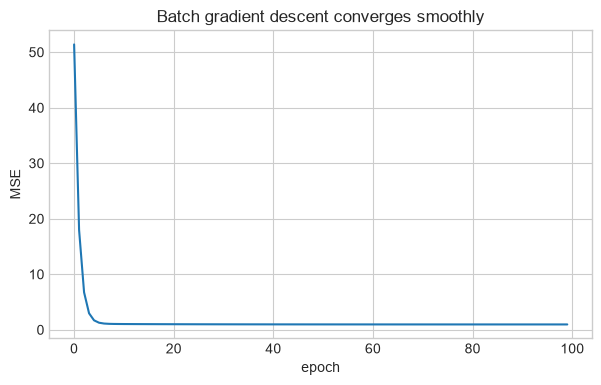

In [5]:
def batch_gradient_descent(X_design, target, learning_rate=0.1, epochs=1_000):
    theta = np.zeros(X_design.shape[1])
    losses = []
    for _ in range(epochs):
        residuals = X_design @ theta - target
        gradient = 2 / len(X_design) * X_design.T @ residuals
        theta -= learning_rate * gradient
        losses.append(np.mean(residuals**2))
    return theta, losses


theta_bgd, bgd_losses = batch_gradient_descent(X_b, y)
print("Batch GD parameters:", np.round(theta_bgd, 3))
print("Pseudoinverse parameters:", np.round(theta_pinv, 3))

plt.figure(figsize=(7, 4))
plt.plot(bgd_losses[:100])
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Batch gradient descent converges smoothly")
plt.show()

### 3.2 Stochastic Gradient Descent (SGD)

SGD 每一步只随机使用一个样本。它更新快、可以在线学习，也更容易跳出局部低谷；代价是损失会抖动，最终参数不会安静地停在最小点。

`SGDRegressor` 的 `max_iter` 对应遍历训练集的次数，`tol=None` 让实验使用固定轮数。`eta0` 是初始学习率，`learning_rate="invscaling"` 让步长随训练逐渐减小。

In [6]:
sgd_model = make_pipeline(
    StandardScaler(),
    SGDRegressor(
        max_iter=1_000,
        tol=None,
        penalty=None,
        eta0=0.1,
        learning_rate="invscaling",
        random_state=RANDOM_STATE,
    ),
)
sgd_model.fit(X, y)

sgd_predictions = sgd_model.predict(X)
print(f"SGD training RMSE: {mean_squared_error(y, sgd_predictions) ** 0.5:.3f}")
print("SGD is especially useful for very large or streaming datasets.")

SGD training RMSE: 0.979
SGD is especially useful for very large or streaming datasets.


### 3.3 Mini-batch Gradient Descent

Mini-batch GD 每步使用一小批样本，是 Batch GD 的稳定性与 SGD 的速度之间的折中，也是现代深度学习最常见的训练方式。

Mini-batch GD parameters: [3.941 3.082]


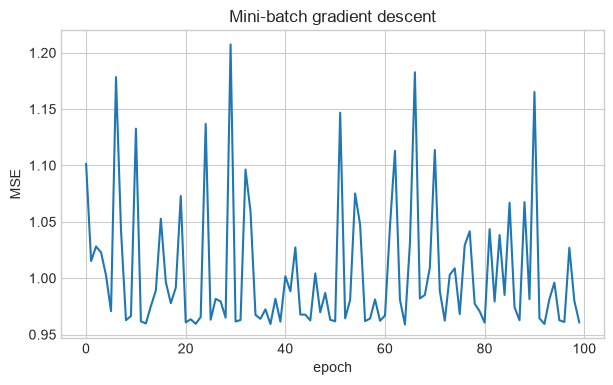

In [7]:
def mini_batch_gradient_descent(
    X_design, target, learning_rate=0.1, epochs=100, batch_size=16
):
    theta = np.zeros(X_design.shape[1])
    losses = []
    for epoch in range(epochs):
        indices = rng.permutation(len(X_design))
        X_shuffled = X_design[indices]
        y_shuffled = target[indices]
        for start in range(0, len(X_design), batch_size):
            X_batch = X_shuffled[start : start + batch_size]
            y_batch = y_shuffled[start : start + batch_size]
            residuals = X_batch @ theta - y_batch
            gradient = 2 / len(X_batch) * X_batch.T @ residuals
            theta -= learning_rate * gradient
        losses.append(np.mean((X_design @ theta - target) ** 2))
    return theta, losses


theta_mbgd, mbgd_losses = mini_batch_gradient_descent(X_b, y)
print("Mini-batch GD parameters:", np.round(theta_mbgd, 3))

plt.figure(figsize=(7, 4))
plt.plot(mbgd_losses)
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Mini-batch gradient descent")
plt.show()

### 三种 Gradient Descent 的对比

| 方法 | 每次更新使用的数据 | 优点 | 代价 |
|---|---:|---|---|
| Batch GD | 全部样本 | 路径稳定、梯度准确 | 大数据时每步昂贵 |
| SGD | 1 个样本 | 更新快、支持在线学习 | 噪声大，需要学习率调度 |
| Mini-batch GD | 一小批样本 | 速度与稳定性的平衡，适合 GPU | 需要选择 batch size |

## 4. Polynomial Regression

线性模型不等于只能拟合直线。先把 $x$ 转换成 $x,x^2,\ldots,x^d$，再对这些新特征做线性回归，就能拟合非线性关系：

$$
\hat y = \theta_0 + \theta_1x + \theta_2x^2
$$

模型对参数仍然是线性的，所以仍叫线性模型。

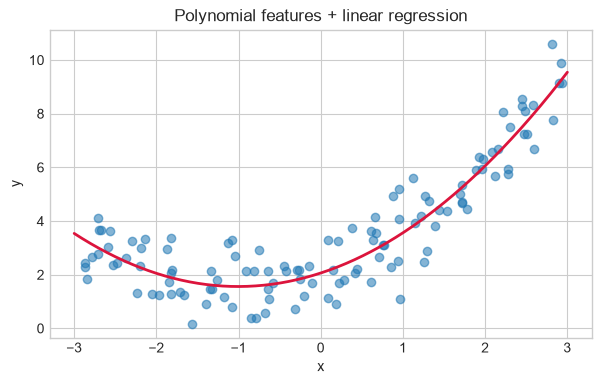

In [8]:
X_poly_data = 6 * rng.random((120, 1)) - 3
y_poly_data = 0.5 * X_poly_data[:, 0] ** 2 + X_poly_data[:, 0] + 2
y_poly_data += rng.normal(0, 1, len(X_poly_data))

quadratic_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression(),
)
quadratic_model.fit(X_poly_data, y_poly_data)

X_curve = np.linspace(-3, 3, 300).reshape(-1, 1)
plt.figure(figsize=(7, 4))
plt.scatter(X_poly_data, y_poly_data, alpha=0.55, label="samples")
plt.plot(X_curve, quadratic_model.predict(X_curve), color="crimson", linewidth=2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Polynomial features + linear regression")
plt.show()

## 5. Learning Curves

Learning curve 画出训练集变大时，训练误差和验证误差如何变化：

- 两条曲线都高且接近：**underfitting / high bias**。
- 训练误差低、验证误差明显更高：**overfitting / high variance**。
- 增加数据通常更能缓解 variance，而不能修复明显的 bias。

下面比较一次模型与十次模型。为避免测试集参与模型选择，这里只划分 training/validation set。

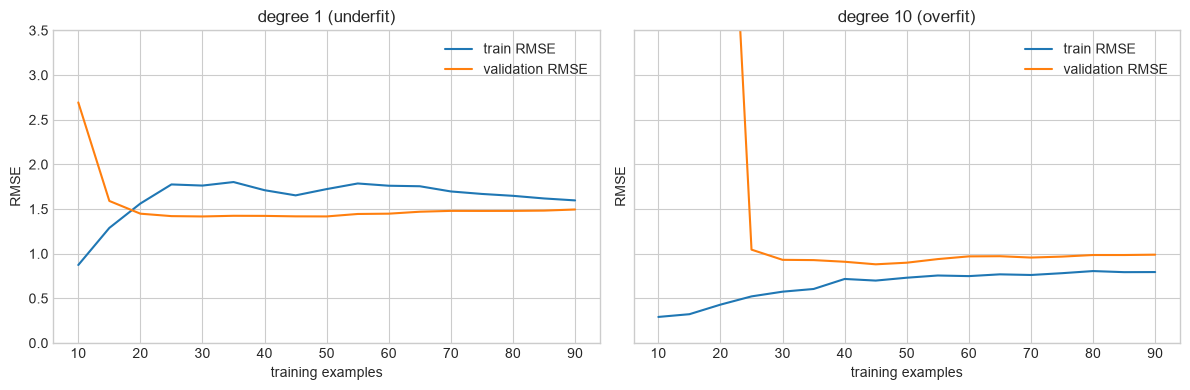

In [9]:
X_train_poly, X_valid_poly, y_train_poly, y_valid_poly = train_test_split(
    X_poly_data,
    y_poly_data,
    test_size=0.25,
    random_state=RANDOM_STATE,
)


def learning_curve_errors(model, X_train, y_train, X_valid, y_valid):
    train_errors, valid_errors = [], []
    for size in range(10, len(X_train) + 1, 5):
        model.fit(X_train[:size], y_train[:size])
        train_errors.append(
            mean_squared_error(y_train[:size], model.predict(X_train[:size])) ** 0.5
        )
        valid_errors.append(
            mean_squared_error(y_valid, model.predict(X_valid)) ** 0.5
        )
    return np.arange(10, len(X_train) + 1, 5), train_errors, valid_errors


learning_models = {
    "degree 1 (underfit)": LinearRegression(),
    "degree 10 (overfit)": make_pipeline(
        PolynomialFeatures(degree=10, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for axis, (name, model) in zip(axes, learning_models.items()):
    sizes, train_errors, valid_errors = learning_curve_errors(
        model, X_train_poly, y_train_poly, X_valid_poly, y_valid_poly
    )
    axis.plot(sizes, train_errors, label="train RMSE")
    axis.plot(sizes, valid_errors, label="validation RMSE")
    axis.set(title=name, xlabel="training examples", ylabel="RMSE", ylim=(0, 3.5))
    axis.legend()
plt.tight_layout()
plt.show()

## 6. Regularized Linear Models

正则化在原损失上加入对参数大小的惩罚，以降低 variance。截距通常不参与惩罚；特征尺度会影响惩罚强度，所以正则化前通常要标准化。

### Ridge Regression — $\ell_2$

$$
J(\boldsymbol{\theta})
= \operatorname{MSE}(\boldsymbol{\theta})
+ \alpha\sum_{j=1}^{n}\theta_j^2
$$

Ridge 会平滑地缩小系数，但通常不会把它们压成精确的 0。

### Lasso Regression — $\ell_1$

$$
J(\boldsymbol{\theta})
= \operatorname{MSE}(\boldsymbol{\theta})
+ \alpha\sum_{j=1}^{n}|\theta_j|
$$

Lasso 倾向于把部分系数压到 0，因此能产生稀疏模型并隐式选择特征。

### Elastic Net

$$
J = \operatorname{MSE}
+ r\alpha\sum|\theta_j|
+ \frac{1-r}{2}\alpha\sum\theta_j^2
$$

`l1_ratio=r`：$r=1$ 是 Lasso，$r=0$ 接近 Ridge。Elastic Net 在特征高度相关时通常比纯 Lasso 更稳定。

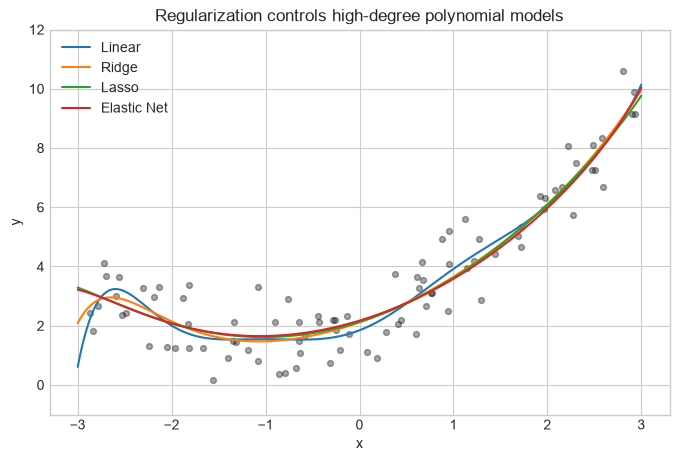

,model,train RMSE,validation RMSE
3,Elastic Net,0.834,0.894
2,Lasso,0.829,0.912
1,Ridge,0.811,0.930
0,Linear,0.795,0.989


In [10]:
regularized_models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.05, max_iter=20_000),
    "Elastic Net": ElasticNet(alpha=0.05, l1_ratio=0.5, max_iter=20_000),
}

regularization_rows = []
plt.figure(figsize=(8, 5))

for name, estimator in regularized_models.items():
    model = make_pipeline(
        PolynomialFeatures(degree=10, include_bias=False),
        StandardScaler(),
        estimator,
    )
    model.fit(X_train_poly, y_train_poly)
    train_rmse = mean_squared_error(y_train_poly, model.predict(X_train_poly)) ** 0.5
    valid_rmse = mean_squared_error(y_valid_poly, model.predict(X_valid_poly)) ** 0.5
    regularization_rows.append(
        {"model": name, "train RMSE": train_rmse, "validation RMSE": valid_rmse}
    )
    plt.plot(X_curve, model.predict(X_curve), label=name)

plt.scatter(X_train_poly, y_train_poly, color="black", alpha=0.35, s=18)
plt.ylim(-1, 12)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Regularization controls high-degree polynomial models")
plt.legend()
plt.show()

pd.DataFrame(regularization_rows).sort_values("validation RMSE").style.format(
    {"train RMSE": "{:.3f}", "validation RMSE": "{:.3f}"}
)

## 7. Early Stopping

对迭代模型，可以在每一轮后测量 validation error，并保留验证误差最低时的模型。这样既限制训练时间，也是一种正则化。

注意：validation set 用于决定何时停止；真正的 test set 仍应保留到最后一次评估。

Best epoch: 13
Best validation RMSE: 0.827


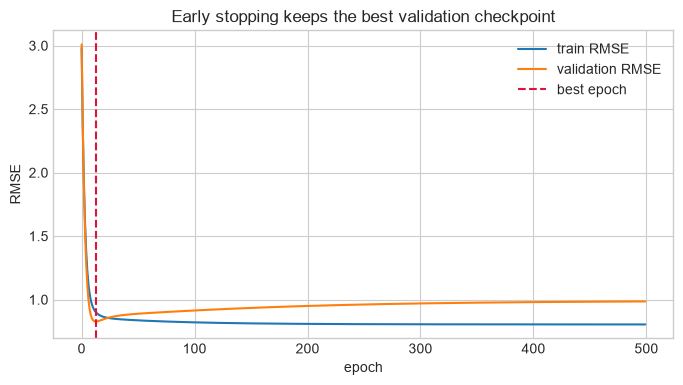

In [11]:
X_train_es, X_valid_es, y_train_es, y_valid_es = train_test_split(
    X_poly_data,
    y_poly_data,
    test_size=0.25,
    random_state=RANDOM_STATE,
)
feature_pipeline = make_pipeline(
    PolynomialFeatures(degree=10, include_bias=False),
    StandardScaler(),
)
X_train_es_scaled = feature_pipeline.fit_transform(X_train_es)
X_valid_es_scaled = feature_pipeline.transform(X_valid_es)

iterative_model = SGDRegressor(
    max_iter=1,
    tol=None,
    warm_start=True,
    penalty=None,
    eta0=0.003,
    learning_rate="constant",
    random_state=RANDOM_STATE,
)

train_errors, valid_errors = [], []
best_epoch = 0
best_valid_rmse = np.inf
best_model = None

for epoch in range(500):
    iterative_model.fit(X_train_es_scaled, y_train_es)
    train_rmse = mean_squared_error(
        y_train_es, iterative_model.predict(X_train_es_scaled)
    ) ** 0.5
    valid_rmse = mean_squared_error(
        y_valid_es, iterative_model.predict(X_valid_es_scaled)
    ) ** 0.5
    train_errors.append(train_rmse)
    valid_errors.append(valid_rmse)

    if valid_rmse < best_valid_rmse:
        best_epoch = epoch
        best_valid_rmse = valid_rmse
        best_model = copy.deepcopy(iterative_model)

print(f"Best epoch: {best_epoch}")
print(f"Best validation RMSE: {best_valid_rmse:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(train_errors, label="train RMSE")
plt.plot(valid_errors, label="validation RMSE")
plt.axvline(best_epoch, color="crimson", linestyle="--", label="best epoch")
plt.xlabel("epoch")
plt.ylabel("RMSE")
plt.title("Early stopping keeps the best validation checkpoint")
plt.legend()
plt.show()

## 8. Logistic Regression

Logistic Regression 是分类模型。它先计算线性分数：

$$
z = \boldsymbol{\theta}^{\mathsf T}\mathbf x
$$

再通过 sigmoid 把分数映射成概率：

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

若 $\hat p\ge 0.5$，通常预测正类。训练时最小化 binary cross-entropy（log loss），而不是 MSE：

$$
-\frac{1}{m}\sum_{i=1}^{m}
\left[y^{(i)}\log\hat p^{(i)}+(1-y^{(i)})\log(1-\hat p^{(i)})\right]
$$

下面只用 Iris 的 petal width 判断是否为 Iris virginica。

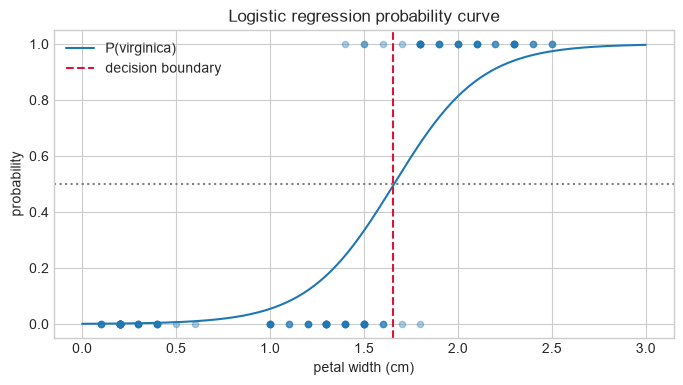

Approximate 0.5 decision boundary: 1.66 cm
Training accuracy: 0.960


In [12]:
iris = load_iris()
X_iris_binary = iris.data[:, [3]]
y_iris_binary = (iris.target == 2).astype(int)

logistic_model = LogisticRegression(random_state=RANDOM_STATE)
logistic_model.fit(X_iris_binary, y_iris_binary)

petal_widths = np.linspace(0, 3, 300).reshape(-1, 1)
probabilities = logistic_model.predict_proba(petal_widths)[:, 1]
decision_boundary = petal_widths[np.argmin(np.abs(probabilities - 0.5)), 0]

plt.figure(figsize=(8, 4))
plt.plot(petal_widths, probabilities, label="P(virginica)")
plt.axhline(0.5, color="gray", linestyle=":")
plt.axvline(decision_boundary, color="crimson", linestyle="--", label="decision boundary")
plt.scatter(X_iris_binary[:, 0], y_iris_binary, alpha=0.35, s=20)
plt.xlabel("petal width (cm)")
plt.ylabel("probability")
plt.title("Logistic regression probability curve")
plt.legend()
plt.show()

print(f"Approximate 0.5 decision boundary: {decision_boundary:.2f} cm")
print(f"Training accuracy: {accuracy_score(y_iris_binary, logistic_model.predict(X_iris_binary)):.3f}")

## 9. Softmax Regression

Softmax Regression 把 Logistic Regression 推广到多个互斥类别。每个类别 $k$ 有一个分数：

$$
s_k(\mathbf x)=\boldsymbol{\theta}_k^{\mathsf T}\mathbf x
$$

softmax 将所有分数归一化为概率：

$$
\hat p_k = \frac{e^{s_k}}{\sum_{j=1}^{K}e^{s_j}}
$$

最终选择概率最大的类别，并使用 multiclass cross-entropy 训练。Softmax 假设每个样本只属于一个类别，因此不适合 multilabel 问题。

In [13]:
X_iris = iris.data[:, 2:4]
y_iris = iris.target

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris,
    y_iris,
    test_size=0.25,
    stratify=y_iris,
    random_state=RANDOM_STATE,
)

softmax_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=10, random_state=RANDOM_STATE),
)
softmax_model.fit(X_train_iris, y_train_iris)

test_probabilities = softmax_model.predict_proba(X_test_iris)
softmax_predictions = softmax_model.predict(X_test_iris)

print(f"Test accuracy: {accuracy_score(y_test_iris, softmax_predictions):.3f}")
print("First five probability vectors (each row sums to 1):")
display(pd.DataFrame(test_probabilities[:5], columns=iris.target_names).round(3))
print("Row sums:", np.round(test_probabilities[:5].sum(axis=1), 6))

Test accuracy: 0.947
First five probability vectors (each row sums to 1):


,setosa,versicolor,virginica
0,0.996,0.004,0.000
1,0.000,0.714,0.285
2,0.004,0.987,0.009
3,0.005,0.988,0.007
4,0.996,0.004,0.000


Row sums: [1. 1. 1. 1. 1.]


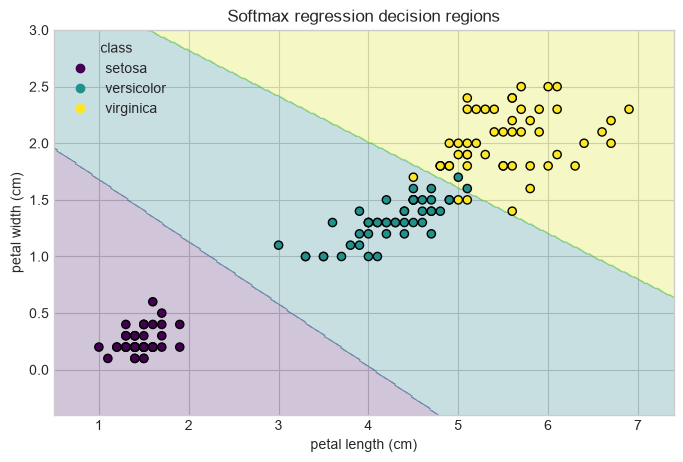

In [14]:
x0, x1 = np.meshgrid(
    np.linspace(X_iris[:, 0].min() - 0.5, X_iris[:, 0].max() + 0.5, 300),
    np.linspace(X_iris[:, 1].min() - 0.5, X_iris[:, 1].max() + 0.5, 300),
)
grid = np.c_[x0.ravel(), x1.ravel()]
grid_predictions = softmax_model.predict(grid).reshape(x0.shape)

plt.figure(figsize=(8, 5))
plt.contourf(x0, x1, grid_predictions, alpha=0.25, cmap="viridis")
scatter = plt.scatter(
    X_iris[:, 0],
    X_iris[:, 1],
    c=y_iris,
    cmap="viridis",
    edgecolor="black",
    s=35,
)
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.title("Softmax regression decision regions")
plt.legend(scatter.legend_elements()[0], iris.target_names, title="class")
plt.show()

## 10. Chapter Summary

- **Linear Regression**：用线性组合预测连续值，常以 MSE 为目标。
- **Normal Equation / pseudoinverse**：直接求最小二乘解；pseudoinverse 对奇异矩阵更稳健。
- **Gradient Descent**：沿负梯度更新参数；Batch、SGD、Mini-batch 在稳定性与计算成本间取舍。
- **Polynomial Regression**：通过特征展开让线性模型表达非线性关系。
- **Learning curves**：区分 high bias 与 high variance，并判断增加数据是否可能有帮助。
- **Ridge / Lasso / Elastic Net**：通过限制参数大小降低过拟合；Lasso 可产生稀疏解。
- **Early stopping**：保留 validation error 最低时的迭代模型，是高效正则化方法。
- **Logistic Regression**：用 sigmoid 建模二分类概率。
- **Softmax Regression**：用一组归一化概率处理互斥多分类。

整章最值得记住的统一视角是：

$$
\boxed{
\boldsymbol{\theta}^{*}
= \arg\min_{\boldsymbol{\theta}}
\left(\text{data loss}+\text{regularization penalty}\right)
}
$$

不同模型的主要差异，在于预测函数、损失函数、正则化方式与优化算法。